In [ ]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

Task 1: Missing Data Check

In [ ]:
# Load dataset
df = pd.read_csv("loan_data.csv")

# Check number of missing values per column
df.isnull().sum()

,0
person_age,0
person_gender,0
person_education,0
person_income,0
person_emp_exp,0
person_home_ownership,0
loan_amnt,0
loan_intent,0
loan_int_rate,0
loan_percent_income,0


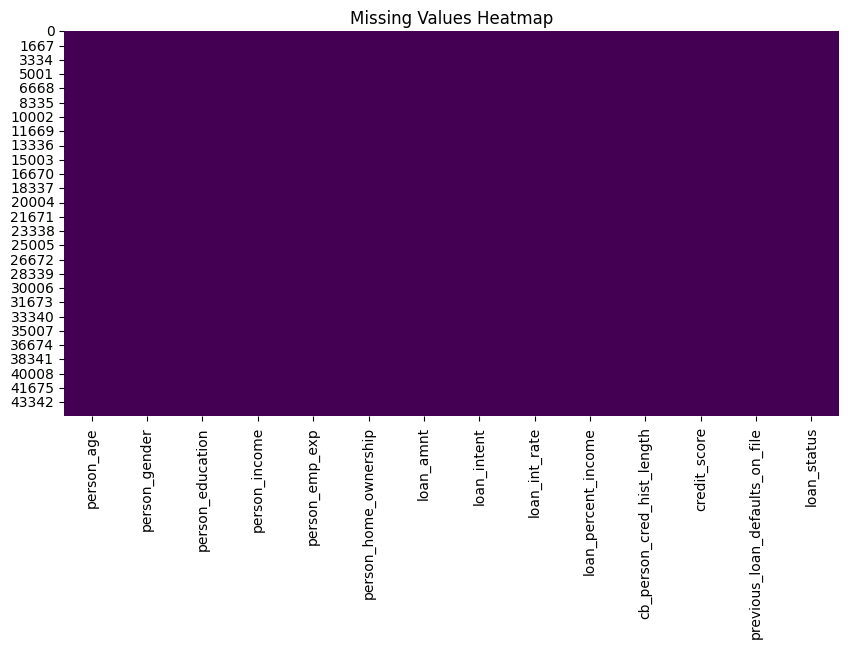

In [ ]:
#Visualize missing values
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

Task 2: Outlier Detection & Removal

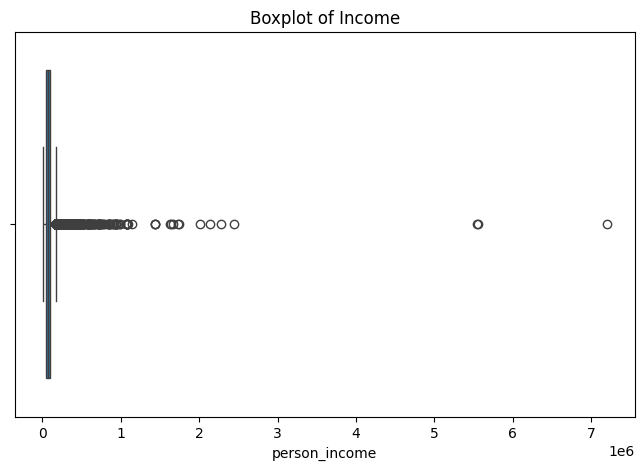

In [ ]:
# 1. Visualize outliers with boxplot
plt.figure(figsize=(8,5))
sns.boxplot(x=df['person_income'])
plt.title("Boxplot of Income")
plt.show()

In [ ]:
# 2. Use IQR method to detect outliers in person_income
Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -25673.875
Upper Bound: 168667.125


In [ ]:
# 3. Remove outliers
df_clean = df[(df['person_income'] >= lower_bound) & (df['person_income'] <= upper_bound)].copy()

In [ ]:
print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original shape: (45000, 14)
After outlier removal: (42782, 14)


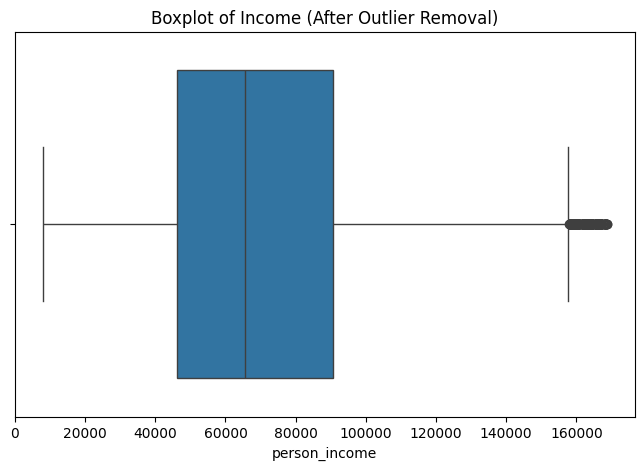

In [ ]:
# After removing outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df_clean['person_income'])
plt.title("Boxplot of Income (After Outlier Removal)")
plt.show()

Task 3: Encoding Categorical Variables

In [ ]:
# Identify categorical columns
cat_cols = df_clean.select_dtypes(include='object').columns
print("Categorical Columns:", cat_cols.tolist())

Categorical Columns: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']


In [ ]:
# Label Encode binary categories
le = LabelEncoder()
df_clean['person_gender'] = le.fit_transform(df_clean['person_gender'])  # male/female
df_clean['previous_loan_defaults_on_file'] = le.fit_transform(df_clean['previous_loan_defaults_on_file'])  # yes/no

In [ ]:
# One-Hot Encode multi-class categorical variables
df_clean = pd.get_dummies(df_clean,
                           columns=['person_education','person_home_ownership','loan_intent'],
                           drop_first=True)

In [ ]:
df_clean.head()

,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,22,0,71948,0,35000,16.02,0.49,3,561,0,...,False,True,False,False,True,False,False,False,True,False
1,21,0,12282,0,1000,11.14,0.08,2,504,1,...,True,False,False,True,False,True,False,False,False,False
2,25,0,12438,3,5500,12.87,0.44,3,635,0,...,True,False,False,False,False,False,False,True,False,False
3,23,0,79753,0,35000,15.23,0.44,2,675,0,...,False,False,False,False,True,False,False,True,False,False
4,24,1,66135,1,35000,14.27,0.53,4,586,0,...,False,True,False,False,True,False,False,True,False,False


Task 4: Feature Scaling

In [ ]:
# Numeric columns
num_cols = ['person_age','person_income','person_emp_exp',
            'loan_amnt','loan_int_rate','loan_percent_income',
            'cb_person_cred_hist_length','credit_score']

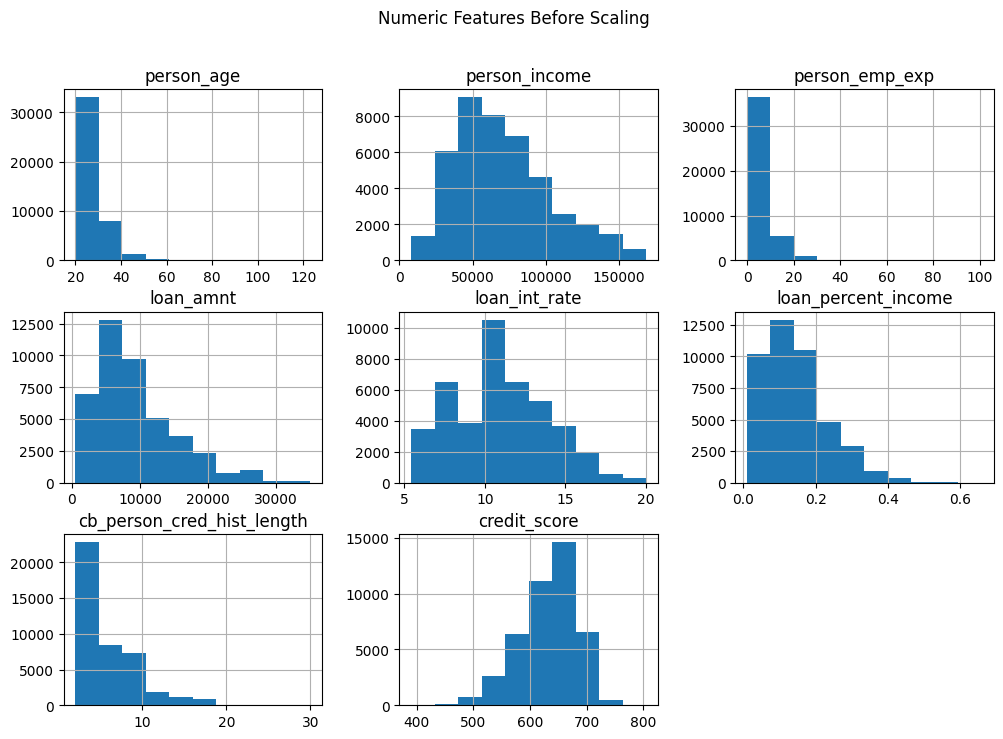

In [ ]:
# Histograms before scaling
df_clean[num_cols].hist(figsize=(12,8))
plt.suptitle("Numeric Features Before Scaling")
plt.show()

In [ ]:
# Apply StandardScaler
scaler = StandardScaler()
df_clean[num_cols] = scaler.fit_transform(df_clean[num_cols])

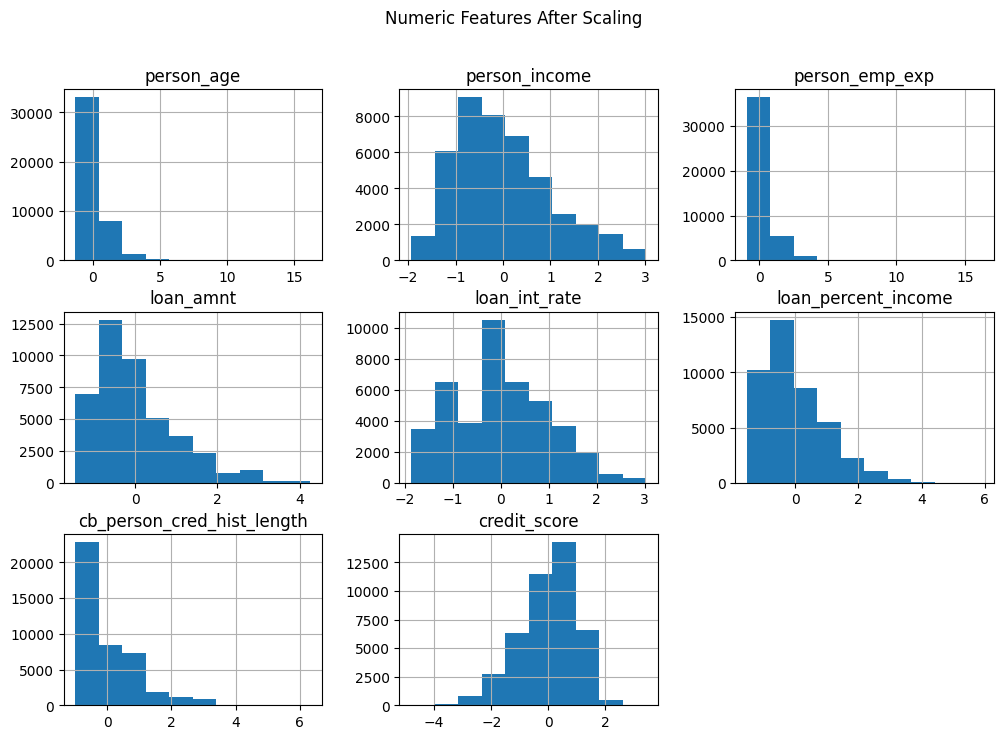

In [ ]:
# Histograms after scaling
df_clean[num_cols].hist(figsize=(12,8))
plt.suptitle("Numeric Features After Scaling")
plt.show()

Task 5: Feature Engineering & EDA

In [ ]:
# Debt-to-Income Ratio
df_clean['debt_to_income_ratio'] = df_clean['loan_amnt'] / df_clean['person_income']

In [ ]:
# Age groups
bins = [18, 30, 50, 65, 100]
labels = ['Young','Adult','Senior','Elder']
df_clean['age_group'] = pd.cut(df_clean['person_age'], bins=bins, labels=labels)

In [ ]:
# One-Hot Encode age_group
df_clean = pd.get_dummies(df_clean, columns=['age_group'], drop_first=True)

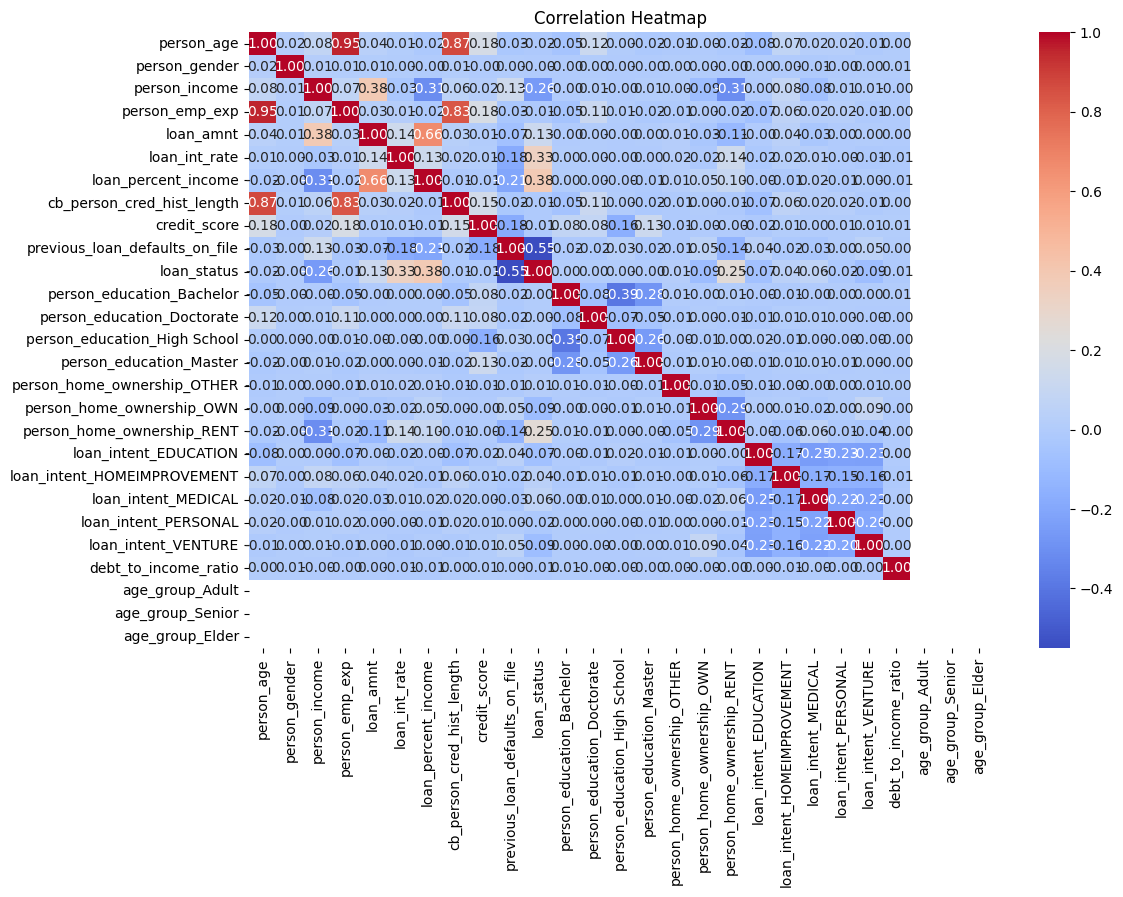

In [ ]:
# Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

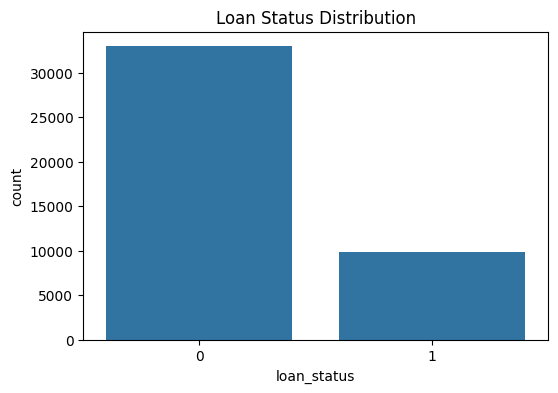

In [ ]:
# Class balance
plt.figure(figsize=(6,4))
sns.countplot(x='loan_status', data=df_clean)
plt.title("Loan Status Distribution")
plt.show()

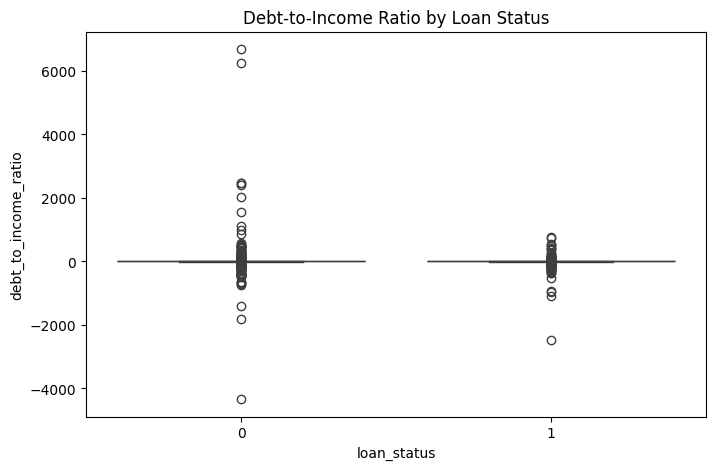

In [ ]:
# Debt-to-Income vs Loan Status
plt.figure(figsize=(8,5))
sns.boxplot(x='loan_status', y='debt_to_income_ratio', data=df_clean)
plt.title("Debt-to-Income Ratio by Loan Status")
plt.show()

Task 6: Feature Selection

In [ ]:
# Correlation with target variable
corr_target = df_clean.corr()['loan_status'].sort_values(ascending=False)
print("Correlation with loan_status:\n", corr_target)

Correlation with loan_status:
 loan_status                       1.000000
loan_percent_income               0.384279
loan_int_rate                     0.333978
person_home_ownership_RENT        0.252931
loan_amnt                         0.127399
loan_intent_MEDICAL               0.062270
loan_intent_HOMEIMPROVEMENT       0.038198
person_home_ownership_OTHER       0.014379
person_education_Bachelor         0.004574
person_education_High School      0.001427
person_education_Doctorate        0.001288
person_gender                    -0.001688
person_education_Master          -0.004750
credit_score                     -0.005893
debt_to_income_ratio             -0.006077
cb_person_cred_hist_length       -0.009605
person_emp_exp                   -0.014742
person_age                       -0.015574
loan_intent_PERSONAL             -0.020633
loan_intent_EDUCATION            -0.066212
loan_intent_VENTURE              -0.085165
person_home_ownership_OWN        -0.094977
person_income          

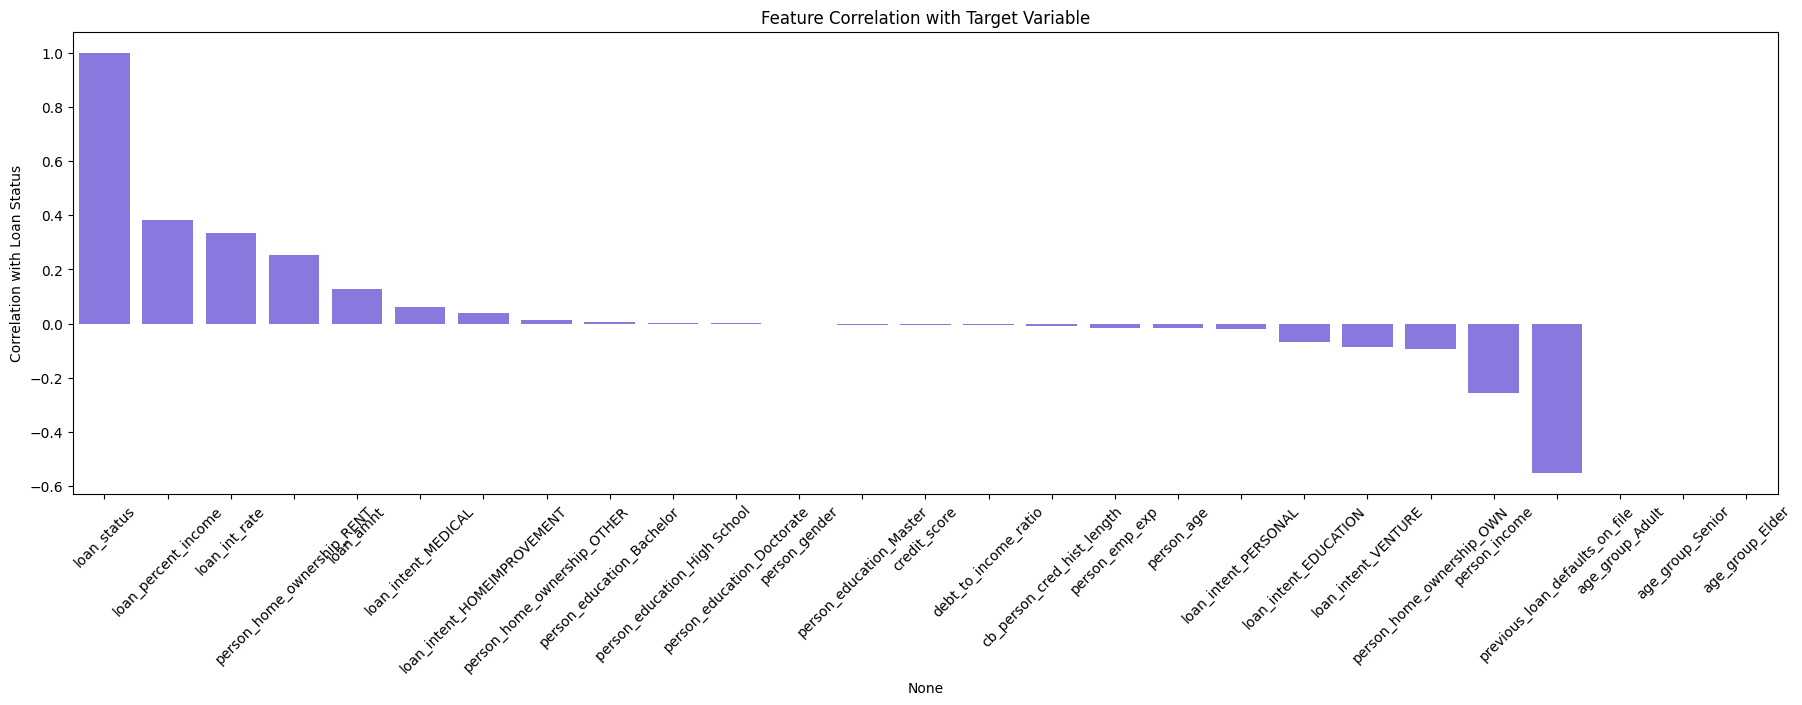

In [ ]:
# Bar plot
plt.figure(figsize=(22,6))
sns.barplot(
    x=corr_target.index,
    y=corr_target.values,
    color="mediumslateblue"
)
plt.xticks(rotation=45)
plt.ylabel("Correlation with Loan Status")
plt.title("Feature Correlation with Target Variable")
plt.show()

In [ ]:
df_final = df_clean.copy()

print("----- First 5 rows of final dataset -----")
display(df_final.head())

----- First 5 rows of final dataset -----


,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,debt_to_income_ratio,age_group_Adult,age_group_Senior,age_group_Elder
0,-0.954301,0,0.033638,-0.893596,4.257362,1.689572,3.964332,-0.726387,-1.414790,0,...,True,False,False,False,True,False,126.562468,False,False,False
1,-1.124179,0,-1.805044,-0.893596,-1.369744,0.049385,-0.724671,-0.987541,-2.545274,1,...,False,True,False,False,False,False,0.758842,False,False,False
2,-0.444668,0,-1.800237,-0.385040,-0.624980,0.630845,3.392503,-0.726387,0.052856,0,...,False,False,False,True,False,False,0.347165,False,False,False
3,-0.784423,0,0.274159,-0.893596,4.257362,1.424050,3.392503,-0.987541,0.846178,0,...,True,False,False,True,False,False,15.528790,False,False,False
4,-0.614545,1,-0.145496,-0.724077,4.257362,1.101390,4.421796,-0.465233,-0.918964,0,...,True,False,False,True,False,False,-29.260932,False,False,False


Advanced Feature Selection

In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

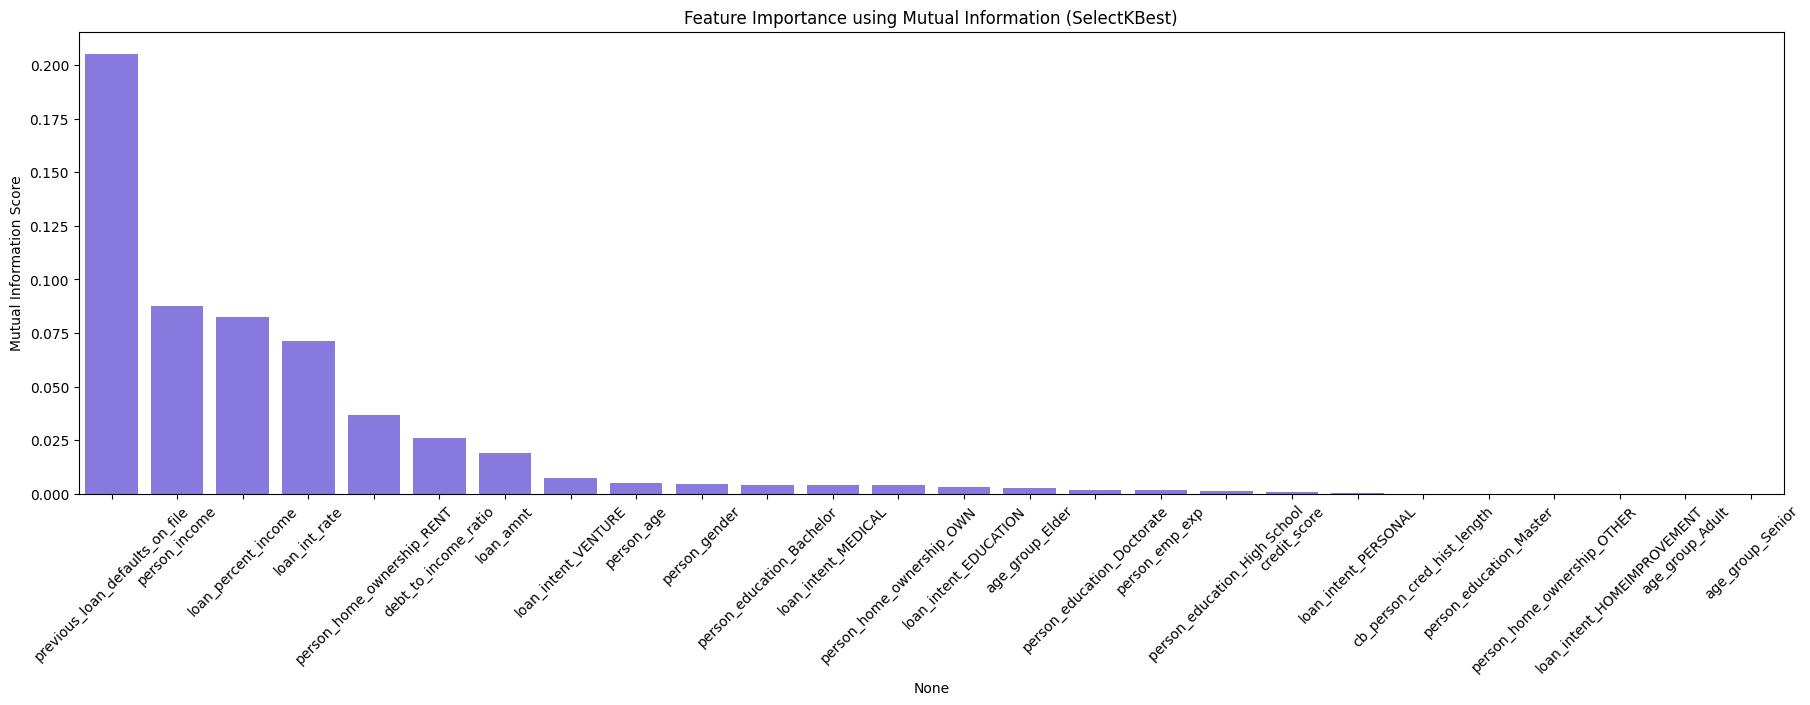

In [ ]:
X = df_final.drop('loan_status', axis=1)
y = df_final['loan_status']

# SelectKBest with Mutual Information
kbest_selector = SelectKBest(score_func=mutual_info_classif, k='all')
kbest_selector.fit(X, y)
kbest_scores = pd.Series(kbest_selector.scores_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(22,6))
sns.barplot(x=kbest_scores.index, y=kbest_scores.values, color="mediumslateblue")
plt.xticks(rotation=45)
plt.ylabel("Mutual Information Score")
plt.title("Feature Importance using Mutual Information (SelectKBest)")
plt.show()

Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_OWN', 'person_home_ownership_RENT',
       'loan_intent_HOMEIMPROVEMENT', 'debt_to_income_ratio'],
      dtype='object')


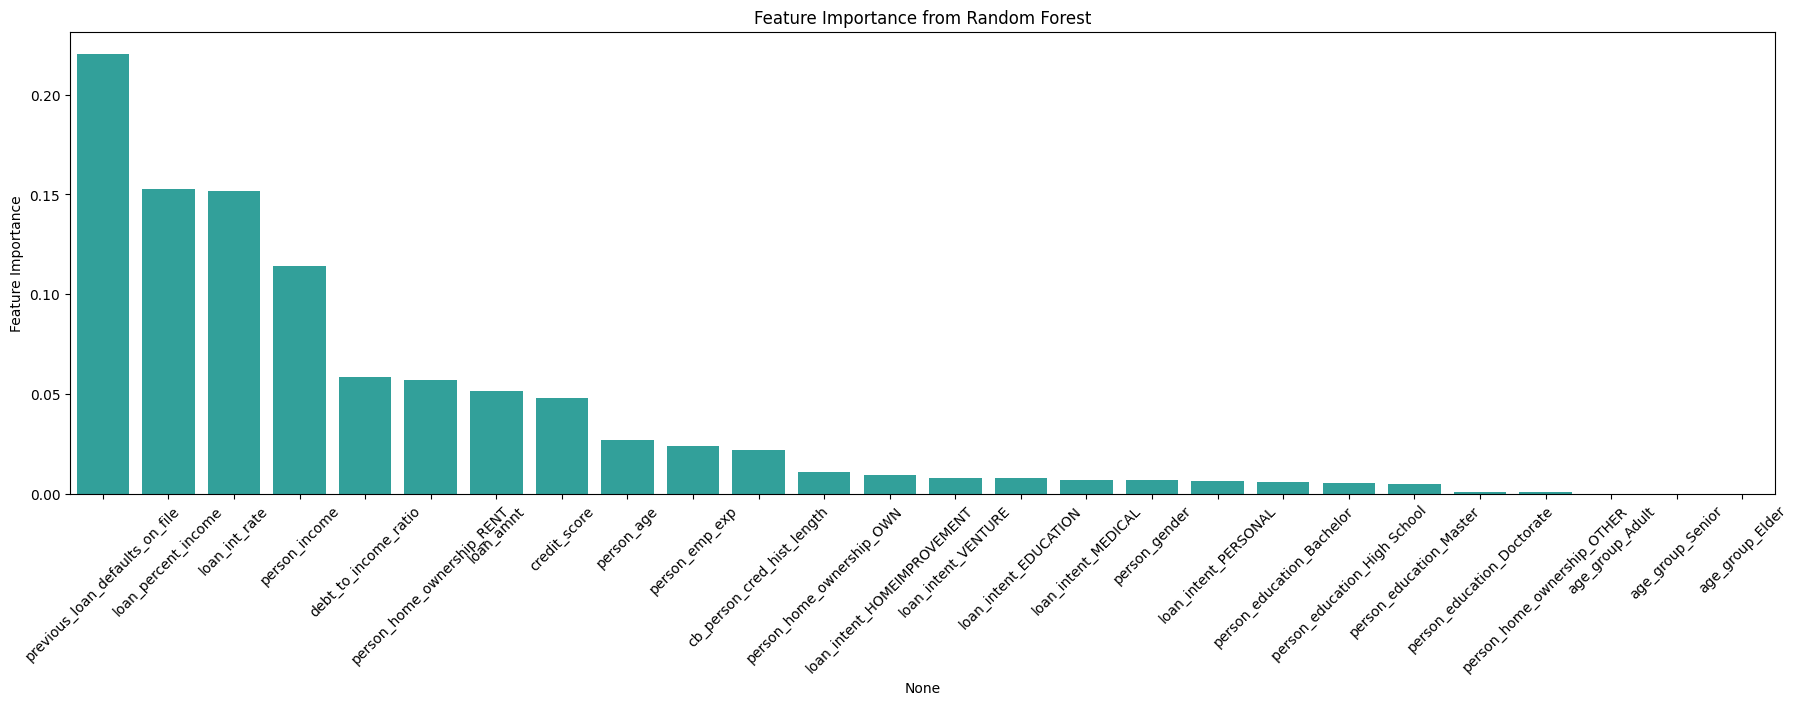

In [ ]:
# Model-Based Feature Selection with Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = X.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(22,6))
sns.barplot(x=importances.index, y=importances.values, color="lightseagreen")
plt.xticks(rotation=45)
plt.ylabel("Feature Importance")
plt.title("Feature Importance from Random Forest")
plt.show()

In [ ]:
# Drop low varaince features with varince threshold
from sklearn.feature_selection import VarianceThreshold

# Apply Variance Threshold
var_thresh = VarianceThreshold(threshold=0.01)  # threshold=0 means drop only constant cols
X_var = var_thresh.fit_transform(X)
kept_after_var = X.columns[var_thresh.get_support()]

print("Features kept after Variance Threshold:", kept_after_var.tolist())

# Identify dropped ones
dropped_by_var = [col for col in X.columns if col not in kept_after_var]
print("Features dropped by Variance Threshold:", dropped_by_var)

Features kept after Variance Threshold: ['person_age', 'person_gender', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'person_education_Bachelor', 'person_education_Doctorate', 'person_education_High School', 'person_education_Master', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'debt_to_income_ratio']
Features dropped by Variance Threshold: ['person_home_ownership_OTHER', 'age_group_Adult', 'age_group_Senior', 'age_group_Elder']


In [ ]:
print("Original shape:", df_final.shape)
print(df_final.head())

Original shape: (42782, 27)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -0.954301              0       0.033638       -0.893596   4.257362   
1   -1.124179              0      -1.805044       -0.893596  -1.369744   
2   -0.444668              0      -1.800237       -0.385040  -0.624980   
3   -0.784423              0       0.274159       -0.893596   4.257362   
4   -0.614545              1      -0.145496       -0.724077   4.257362   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.689572             3.964332                   -0.726387   
1       0.049385            -0.724671                   -0.987541   
2       0.630845             3.392503                   -0.726387   
3       1.424050             3.392503                   -0.987541   
4       1.101390             4.421796                   -0.465233   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.414790                               0  ...   


In [ ]:
# After dropping low variance features
X_var_df = pd.DataFrame(X_var, columns=kept_after_var)
print("Shape after VarianceThreshold:", X_var_df.shape)
print(X_var_df.head())

Shape after VarianceThreshold: (42782, 22)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -0.954301            0.0       0.033638       -0.893596   4.257362   
1   -1.124179            0.0      -1.805044       -0.893596  -1.369744   
2   -0.444668            0.0      -1.800237       -0.385040  -0.624980   
3   -0.784423            0.0       0.274159       -0.893596   4.257362   
4   -0.614545            1.0      -0.145496       -0.724077   4.257362   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.689572             3.964332                   -0.726387   
1       0.049385            -0.724671                   -0.987541   
2       0.630845             3.392503                   -0.726387   
3       1.424050             3.392503                   -0.987541   
4       1.101390             4.421796                   -0.465233   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.414790                          

In [ ]:
df = X_var_df.copy()

In [ ]:
print("New shape:", df.shape)
print(df.head())

New shape: (42782, 22)
   person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0   -0.954301            0.0       0.033638       -0.893596   4.257362   
1   -1.124179            0.0      -1.805044       -0.893596  -1.369744   
2   -0.444668            0.0      -1.800237       -0.385040  -0.624980   
3   -0.784423            0.0       0.274159       -0.893596   4.257362   
4   -0.614545            1.0      -0.145496       -0.724077   4.257362   

   loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
0       1.689572             3.964332                   -0.726387   
1       0.049385            -0.724671                   -0.987541   
2       0.630845             3.392503                   -0.726387   
3       1.424050             3.392503                   -0.987541   
4       1.101390             4.421796                   -0.465233   

   credit_score  previous_loan_defaults_on_file  ...  \
0     -1.414790                             0.0  ...   
1    

In [ ]:
print(df.dtypes)

person_age                        float64
person_gender                     float64
person_income                     float64
person_emp_exp                    float64
loan_amnt                         float64
loan_int_rate                     float64
loan_percent_income               float64
cb_person_cred_hist_length        float64
credit_score                      float64
previous_loan_defaults_on_file    float64
person_education_Bachelor         float64
person_education_Doctorate        float64
person_education_High School      float64
person_education_Master           float64
person_home_ownership_OWN         float64
person_home_ownership_RENT        float64
loan_intent_EDUCATION             float64
loan_intent_HOMEIMPROVEMENT       float64
loan_intent_MEDICAL               float64
loan_intent_PERSONAL              float64
loan_intent_VENTURE               float64
debt_to_income_ratio              float64
dtype: object


In [ ]:
# Train Random Forest on variance-thresholded features
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(df, y)

# Select features above median importance
model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = df.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_RENT', 'debt_to_income_ratio'],
      dtype='object')


In [ ]:
# Create dataset with only selected features
X_final = df[selected_features]

In [ ]:
print("New shape:", X_final.shape)
print(X_final.head())

New shape: (42782, 11)
   person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0   -0.954301       0.033638       -0.893596   4.257362       1.689572   
1   -1.124179      -1.805044       -0.893596  -1.369744       0.049385   
2   -0.444668      -1.800237       -0.385040  -0.624980       0.630845   
3   -0.784423       0.274159       -0.893596   4.257362       1.424050   
4   -0.614545      -0.145496       -0.724077   4.257362       1.101390   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0             3.964332                   -0.726387     -1.414790   
1            -0.724671                   -0.987541     -2.545274   
2             3.392503                   -0.726387      0.052856   
3             3.392503                   -0.987541      0.846178   
4             4.421796                   -0.465233     -0.918964   

   previous_loan_defaults_on_file  person_home_ownership_RENT  \
0                             0.0                         